# Лабораторная работа: Машина опорных векторов (SVM)

## 0. Подготовка ноутбука

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['font.size'] = 12

# фиксируем seed для воспроизводимости случайных экспериментов
np.random.seed(42)

In [2]:
!pip install cvxopt

   ---------------------------------------- 0.0/13.6 MB ? eta -:--:--
    --------------------------------------- 0.3/13.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.6 MB 1.6 MB/s eta 0:00:08
   --- ------------------------------------ 1.3/13.6 MB 2.2 MB/s eta 0:00:06
   ----- ---------------------------------- 1.8/13.6 MB 2.5 MB/s eta 0:00:05
   ------- -------------------------------- 2.6/13.6 MB 2.6 MB/s eta 0:00:05
   --------- ------------------------------ 3.1/13.6 MB 2.7 MB/s eta 0:00:04
   ---------- ----------------------------- 3.7/13.6 MB 2.7 MB/s eta 0:00:04
   ------------ --------------------------- 4.2/13.6 MB 2.6 MB/s eta 0:00:04
   ------------- -------------------------- 4.7/13.6 MB 2.7 MB/s eta 0:00:04
   --------------- ------------------------ 5.2/13.6 MB 2.5 MB/s eta 0:00:04
   --------------- ------------------------ 5.2/13.6 MB 2.5 MB/s eta 0:00:04
   ------------------ --------------------- 6.3/13.6 MB 2.6 MB/s eta 0:00:03
   ----------


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from cvxopt import matrix, solvers

### 1.2. Пример: план кондитерской

In [4]:
c = matrix(np.array([-30.0, -40.0]), tc='d')

G = matrix(np.array([[ 1.0,  2.0],    #  x1 + 2x2 <= 8    (печь)
                     [ 3.0,  2.0],    #  3x1 + 2x2 <= 12  (кондитер)
                     [-1.0,  0.0],    # -x1        <= 0
                     [ 0.0, -1.0]]), tc='d')   # -x2 <= 0
h = matrix(np.array([8.0, 12.0, 0.0, 0.0]), tc='d')

sol_lp = solvers.lp(c, G, h)
print('x* =', np.array(sol_lp['x']).ravel())
print('прибыль =', -sol_lp['primal objective'])

# для самопроверки: должно получиться x* = (2, 3) и прибыль 180

     pcost       dcost       gap    pres   dres   k/t
 0: -1.6571e+02 -3.0000e+02  4e+01  0e+00  6e-01  1e+00
 1: -1.7911e+02 -1.8741e+02  2e+00  1e-16  4e-02  2e-01
 2: -1.7999e+02 -1.8008e+02  2e-02  3e-16  4e-04  2e-03
 3: -1.8000e+02 -1.8000e+02  2e-04  2e-16  4e-06  2e-05
 4: -1.8000e+02 -1.8000e+02  2e-06  4e-16  4e-08  2e-07
Optimal solution found.
x* = [1.99999992 3.00000004]
прибыль = 179.99999908647814


### 1.3. Визуализация: оптимум — в вершине

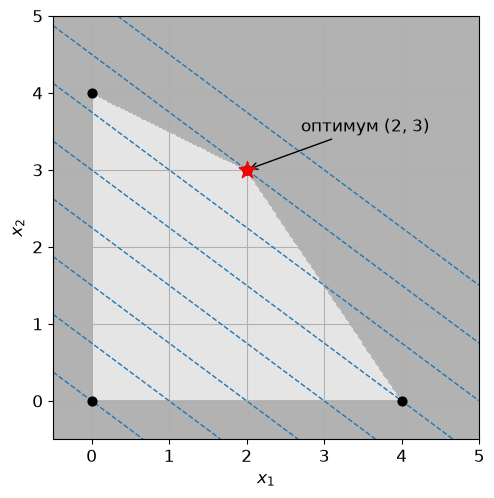

In [5]:
x1 = np.linspace(-0.5, 5.0, 200)
x2 = np.linspace(-0.5, 5.0, 200)
xx1, xx2 = np.meshgrid(x1, x2)

profit = 30*xx1 + 40*xx2
ok = (xx1 + 2*xx2 <= 8) & (3*xx1 + 2*xx2 <= 12) & (xx1 >= 0) & (xx2 >= 0)

vertices = np.array([[0, 0], [4, 0], [2, 3], [0, 4]], dtype=float)

plt.figure(figsize=(5.5, 5.5))
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.contourf(x1, x2, ok, 1, alpha=0.4, cmap='gray')
plt.contour(x1, x2, profit, levels=np.arange(0, 240, 30), colors='tab:blue',
            linestyles='--', linewidths=1)
plt.scatter(vertices[:, 0], vertices[:, 1], color='black', s=40, zorder=3)
plt.scatter([2], [3], color='red', s=160, marker='*', zorder=4)  # оптимум
plt.annotate('оптимум (2, 3)', (2, 3), xytext=(2.7, 3.5),
             arrowprops=dict(arrowstyle='->'))
plt.show()

### 1.5. Знакомство с `cvxopt`

In [6]:
# Внимание: список из шести чисел превратился в матрицу 2x3,
# заполненную ПО СТОЛБЦАМ: первый столбец (1, 2), второй (3, 4), третий (5, 6)
A = matrix([1.0, 2.0, 3.0, 4.0, 5.0, 6.0], (2, 3))
print(A)
print('размер матрицы:', A.size)

# Проще передавать numpy-массивы с параметром tc='d' (числа двойной точности)
B = matrix(np.array([[1.0, 2.0, 3.0],
                     [4.0, 5.0, 6.0]]), tc='d')
print(B)

[ 1.00e+00  3.00e+00  5.00e+00]
[ 2.00e+00  4.00e+00  6.00e+00]

размер матрицы: (2, 3)
[ 1.00e+00  2.00e+00  3.00e+00]
[ 4.00e+00  5.00e+00  6.00e+00]



### 1.6. Первый запуск QP-солвера

In [7]:
P = matrix(np.diag([1.0, 0.0]), tc='d')
q = matrix(np.array([3.0, 4.0]), tc='d')

G = matrix(np.array([[-1.0,  0.0],    # -x1         <= 0     (это x1 >= 0)
                     [ 0.0, -1.0],    # -x2         <= 0     (это x2 >= 0)
                     [-1.0, -3.0],    # -x1 - 3x2   <= -15   (это x1 + 3x2 >= 15)
                     [ 2.0,  5.0],    #  2x1 + 5x2  <= 100
                     [ 3.0,  4.0]]), tc='d')   #  3x1 + 4x2 <= 80
h = matrix(np.array([0.0, 0.0, -15.0, 100.0, 80.0]), tc='d')

sol = solvers.qp(P, q, G, h)
print('x* =', np.array(sol['x']).ravel())
print('f(x*) =', sol['primal objective'])
# для самопроверки: должно получиться примерно x* = (0, 5) и f(x*) = 20

# чтобы солвер не печатал подробный лог при каждом вызове, выполните:
# solvers.options['show_progress'] = False

     pcost       dcost       gap    pres   dres
 0:  1.0780e+02 -7.6366e+02  9e+02  0e+00  4e+01
 1:  9.3245e+01  9.7637e+00  8e+01  1e-16  3e+00
 2:  6.7311e+01  3.2553e+01  3e+01  3e-18  1e+00
 3:  2.6071e+01  1.5068e+01  1e+01  9e-17  7e-01
 4:  3.7092e+01  2.3152e+01  1e+01  1e-16  4e-01
 5:  2.5352e+01  1.8652e+01  7e+00  3e-16  7e-17
 6:  2.0062e+01  1.9974e+01  9e-02  9e-17  7e-17
 7:  2.0001e+01  2.0000e+01  9e-04  6e-17  2e-16
 8:  2.0000e+01  2.0000e+01  9e-06  9e-17  4e-16
Optimal solution found.
x* = [7.13181641e-07 5.00000101e+00]
f(x*) = 20.00000617311241


### 1.7. Активные и неактивные ограничения

In [8]:
G_np = np.array(G)
x_star = np.array(sol['x']).ravel()

for i, (g_row, h_i) in enumerate(zip(G_np, np.array(h).ravel())):
    slack = h_i - g_row @ x_star
    status = 'АКТИВНО' if abs(slack) < 1e-6 else 'неактивно'
    print(f'ограничение {i}:  h - g^T x* = {slack:8.4f}  ->  {status}')

ограничение 0:  h - g^T x* =   0.0000  ->  АКТИВНО
ограничение 1:  h - g^T x* =   5.0000  ->  неактивно
ограничение 2:  h - g^T x* =   0.0000  ->  неактивно
ограничение 3:  h - g^T x* =  75.0000  ->  неактивно
ограничение 4:  h - g^T x* =  60.0000  ->  неактивно


### 1.8. Визуализация QP-задачи (пригодится в задании 1)

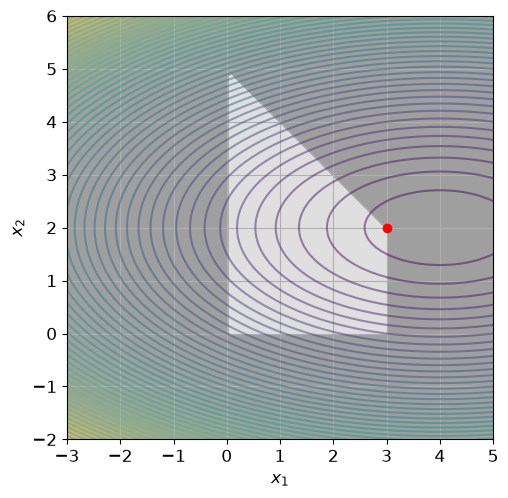

In [9]:
x1 = np.linspace(-3, 5, 100)
x2 = np.linspace(-2, 6, 100)
xx1, xx2 = np.meshgrid(x1, x2)

f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2                      # оптимизируемая функция
ok = (xx1 + xx2 <= 5) & (xx1 >= 0) & (xx1 <= 3) & (xx2 >= 0)  # допустимая область

plt.figure(figsize=(5.5, 5.5))
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.contour(x1, x2, f, 50, alpha=0.5)
plt.contourf(x1, x2, ok, 1, alpha=0.5, cmap='gray')
plt.scatter([3], [2], color='red', zorder=3)  # точка (3, 2): проверьте, что солвер найдёт её же
plt.show()

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 1. Линейное и квадратичное программирование</h2>

### Часть A. Линейное программирование

1. Мебельная мастерская выпускает столы ($x_1$) и стулья ($x_2$). Прибыль: 3 и 2 тыс. руб. за изделие. Цех сборки тратит на стол 2 часа, на стул — 1 час, всего доступно 6 часов; отделка — по 1 часу на любое изделие, всего 4 часа. Составьте задачу LP, переведите максимизацию прибыли в минимизацию и решите её с помощью `solvers.lp`.
2. Нарисуйте допустимую область, линии уровня прибыли и решение (по образцу п. 1.3). Проверьте ответ, перебрав все вершины многоугольника: каждую вершину найдите как решение системы двух линейных уравнений и подставьте в прибыль.
3. Подберите другие коэффициенты прибыли, при которых оптимальным станет **целое ребро** многоугольника, а не одна вершина. Что вернёт солвер в этом случае?

### Часть B. Квадратичное программирование

4. Решите с помощью `solvers.qp` задачу
$$f(\boldsymbol x) = -8x_1 - 16x_2 + x_1^2 + 4x_2^2 \to \min, \qquad
x_1 + x_2 \le 5, \quad 0 \le x_1 \le 3, \quad x_2 \ge 0.$$
   Сначала найдите минимум **без ограничений** (приравняв градиент к нулю) и убедитесь, что он нарушает ограничения. Затем решите задачу с ограничениями и отметьте решение на картинке из п. 1.8.

5. Какие из ограничений **активны**, а какие можно выбросить без изменения решения? Проверьте экспериментально: решите задачу, удалив «лишнее» ограничение, и сравните ответы.

6. Сравните части A и B: в какой задаче оптимум обязан лежать на границе, а в какой может оказаться внутри области? Как это связано с видом целевой функции («плоскость» против «чаши»)?

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 2. Линейный SVM</h2>

1. Сведите задачу обучения линейного SVM к QP (п. 2.4) и реализуйте обучение в классе `LinearSVM` (скелет ниже) при помощи QP-солвера. **Не забудьте:** солверу нужны метки $y_n \in \{+1, -1\}$; если метки закодированы нулями и единицами, преобразуйте их: `y = 2 * y - 1`.
2. Сгенерируйте три случайные двумерные выборки для бинарной классификации:
   - с линейно разделимыми классами;
   - с хорошо разделимыми классами, но **не линейно**;
   - с плохо разделимыми классами по имеющимся признакам.
3. Протестируйте линейный SVM на этих выборках. Покажите на плоскости разделяющую прямую и границы коридора $f(\boldsymbol x) = \pm 1$. Выделите опорные векторы точками другой формы или большего размера. Постройте классификаторы с разными значениями параметра $C$.
4. Как зависит число опорных векторов от параметра $C$ для каждой из выборок? Объясните, почему.
5. Используя явное преобразование признаков (п. 2.5), обучите методом опорных векторов квадратичную разделяющую поверхность и покажите её на плоскости.

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 3. Двойственный SVM и ядра</h2>

1. Реализуйте процедуру обучения ядрового SVM (`DualSVM`) при помощи QP-солвера.
2. Протестируйте ядровой SVM на случайных двумерных выборках (удобно взять те же три, что и в задании 2). Покажите на плоскости разделяющие поверхности, границы коридора $f(\boldsymbol x) = \pm 1$ и опорные векторы. Попробуйте ядра:
   - линейное: $k(x, x') = x^T x'$;
   - полиномиальное: $k(x, x') = (x^T x' + 1)^p$ с различными степенями $p = 2, 3, \dots$;
   - гауссовское RBF: $k(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.
3. Как ведёт себя SVM с полиномиальным ядром при увеличении $C$ и степени ядра $p$?
4. Как ведёт себя SVM с RBF-ядром при вариации $C$ и $\gamma$ (поварьируйте параметры по логарифмической сетке)? Какие значения параметров приводят к переобучению, а какие — к слишком грубой модели? На выборке «полумесяцы» сравните линейное, полиномиальное и RBF-ядра.

## <h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 4. SVM на реальных данных</h2>

1. Выполните загрузку, разведку и подготовку данных по чек-листу п. 4.2. В отчёте покажите таблицу до и после подготовки и поясните каждый шаг.
2. Обучите **свой** `LinearSVM` (из задания 2) на подготовленных данных. Подберите $C$ по логарифмической сетке $10^{-3}, \dots, 10^{5}$: посчитайте accuracy на train и test для каждого значения и изобразите оба графика в зависимости от $\log_{10} C$. Выберите лучшее $C$ и объясните выбор.
3. Обучите **свой** `DualSVM` с RBF-ядром: подберите пару $(C, \gamma)$ по логарифмической сетке (удобно построить тепловую карту качества). Стало ли лучше, чем с линейным SVM? На какой модели и параметрах остановитесь?
4. Проверьте себя: обучите [`sklearn.svm.SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) с `kernel='linear'` и `kernel='rbf'` на тех же данных и гиперпараметрах — качество должно получиться близким к вашему. Если различие велико — ищите ошибку в реализации.
5. Ответьте на вопросы в отчёте:
   - что произойдёт с качеством вашего SVM, если **не** масштабировать признаки? Проверьте экспериментально и объясните результат;
   - какие признаки сильнее всего влияют на диагноз? Для линейной SVM естественная мера важности признака $j$ — модуль веса $\lvert w_j \rvert$: отсортируйте признаки по важности и дайте клиническую интерпретацию — согласуется ли результат с медицинской интуицией (что важнее: боль в груди, возраст или холестерин?);
   - какую долю обучающей выборки составляют опорные векторы и как эта доля зависит от $C$? Много ли пациентов оказываются «на границе» диагноза?